Ячейка 1 (Загрузка и подготовка):

In [1]:
import sys
sys.path.append('..')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from src.clusters import prepare_data, elbow_silhouette, run_dbscan

# Читаем витрину признаков
features = pd.read_parquet('../data/processed/features.parquet')

# Берем числовые признаки для кластеризации
# (важно: НЕ берем target - высоту, чтобы не было утечки!)
cols_for_clustering = [
    'origin_freq', 'typecode_freq', 'origin_count', 'origin_median_alt',
    'callsign_len', 'airline_freq', 'latitude_1', 'longitude_1', 'altitude_1'
]
# Убираем строки с пропусками (если есть)
features_cluster = features[cols_for_clustering].dropna()

# Чтобы не ждать вечность на 7 млн строк, возьмем случайную выборку 50 000
# (Методичка разрешает это: "20-50 тысяч строк с зафиксированным random_state")
sample_size = 50000
if len(features_cluster) > sample_size:
    features_sample = features_cluster.sample(n=sample_size, random_state=42)
    print(f"Используем выборку: {sample_size} строк")
else:
    features_sample = features_cluster
    print(f"Используем весь набор: {len(features_cluster)} строк")

# Стандартизация
X_scaled, _ = prepare_data(features_sample, cols_for_clustering)

Используем выборку: 50000 строк
Стандартизация признаков...


Ячейка 2 (Метод локтя и силуэт):

Перебор k от 2 до 10 (это может занять пару минут)...
k=2: инерция=364460, силуэт=0.183
k=3: инерция=307418, силуэт=0.195
k=4: инерция=265322, силуэт=0.209
k=5: инерция=237034, силуэт=0.205
k=6: инерция=214898, силуэт=0.205
k=7: инерция=198771, силуэт=0.203
k=8: инерция=187323, силуэт=0.205


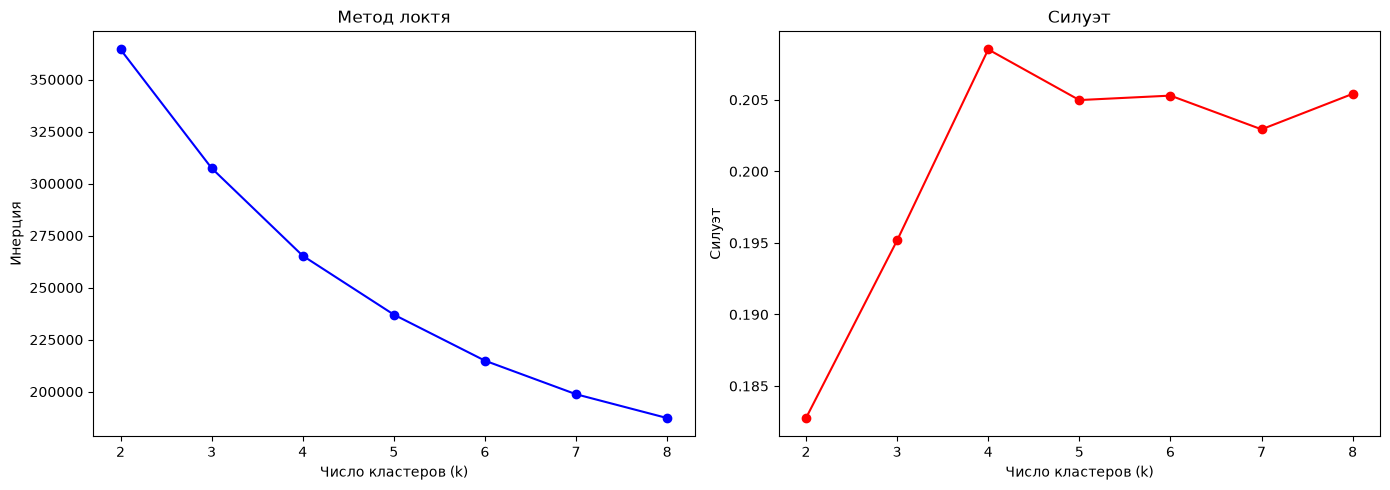

In [2]:
inertia, silhouette = elbow_silhouette(X_scaled, k_range=range(2, 9))

Ячейка 3 (DBSCAN):

In [3]:
# Подбираем eps так, чтобы доля шума была не более 20%
eps_values = [0.5, 1.0, 1.5, 2.0]
for eps in eps_values:
    labels, noise_share = run_dbscan(X_scaled, eps=eps)
    if noise_share <= 0.20:
        print(f"Подходящий eps найден: {eps}")
        break

Запуск DBSCAN (eps=0.5, min_samples=5)...
DBSCAN: кластеров = 1438, доля шума = 11.31%
Подходящий eps найден: 0.5


### Таблица 8 - Подбор числа кластеров

| Метод | Кластеров | Инерция | Силуэт | Доля шума |
| :--- | :--- | :--- | :--- | :--- |
| KMeans, k=2 | 2 | 364460 | 0.183 | — |
| KMeans, k=3 | 3 | 307418 | 0.195 | — |
| **KMeans, k=4** | **4** | **265322** | **0.209** | — |
| KMeans, k=5 | 5 | 237034 | 0.205 | — |
| KMeans, k=6 | 6 | 214898 | 0.205 | — |
| KMeans, k=7 | 7 | 198771 | 0.203 | — |
| KMeans, k=8 | 8 | 187323 | 0.205 | — |
| DBSCAN, eps=0.5 | 1438 | — | — | 11.31% |

**Вывод по подбору числа кластеров:**

Для выбора оптимального числа кластеров были использованы два метода: KMeans (с перебором k от 2 до 8) и DBSCAN.

1. **Метод локтя (инерция):** График инерции показывает плавное снижение без ярко выраженного «излома», что затрудняет однозначный выбор. Однако чем больше k, тем ниже инерция (лучше сжатие).

2. **Силуэт:** Анализ силуэта показал четкий максимум на **k = 4** (значение 0.209). Дальнейшее увеличение k приводит к снижению или стабилизации метрики. Это указывает на то, что 4 кластера — оптимальное разбиение для данных.

3. **DBSCAN:** При eps = 0.5 алгоритм выделил 1438 кластеров, а доля шума составила 11.31% (менее 20%). Однако из-за большого количества мелких кластеров интерпретировать их сложно.

**Итоговый выбор:** Для дальнейшей работы выбран метод **KMeans с k = 4**, так как он показал наилучший силуэт и позволяет четко выделить четыре крупных сегмента для анализа.